In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv("../data/archive/creditcard.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first 5 records
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 284807
Number of columns: 31


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Series([], dtype: int64)

Total missing values: 0


In [7]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)
print("Number of unique records:", df.drop_duplicates().shape[0])

Number of duplicate records: 1081
Number of unique records: 283726


In [8]:
# Create a cleaned copy without duplicate records
df_cleaned = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_cleaned.shape)
print("Duplicates remaining:", df_cleaned.duplicated().sum())

Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)
Duplicates remaining: 0


In [9]:
# Count genuine and fraudulent transactions
class_counts = df_cleaned["Class"].value_counts()

print("Transaction Class Distribution:")
print(class_counts)

# Calculate percentages
class_percentages = df_cleaned["Class"].value_counts(normalize=True) * 100

print("\nClass Distribution Percentage:")
print(class_percentages)

Transaction Class Distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Class Distribution Percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


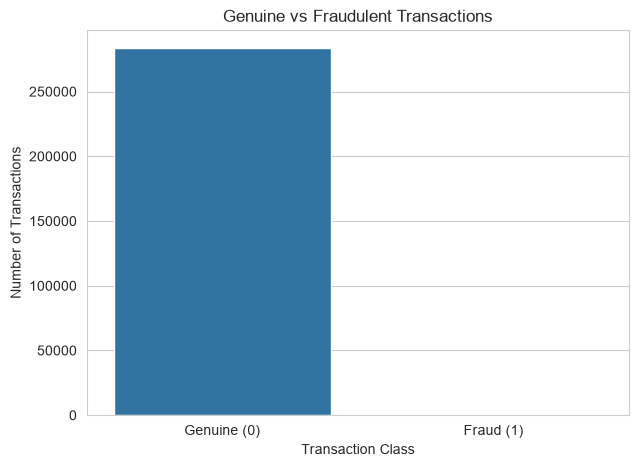

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_cleaned, x="Class")

plt.title("Genuine vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Genuine (0)", "Fraud (1)"])

plt.show()

In [11]:
# Statistical summary of transaction amounts
print(df_cleaned["Amount"].describe())

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64


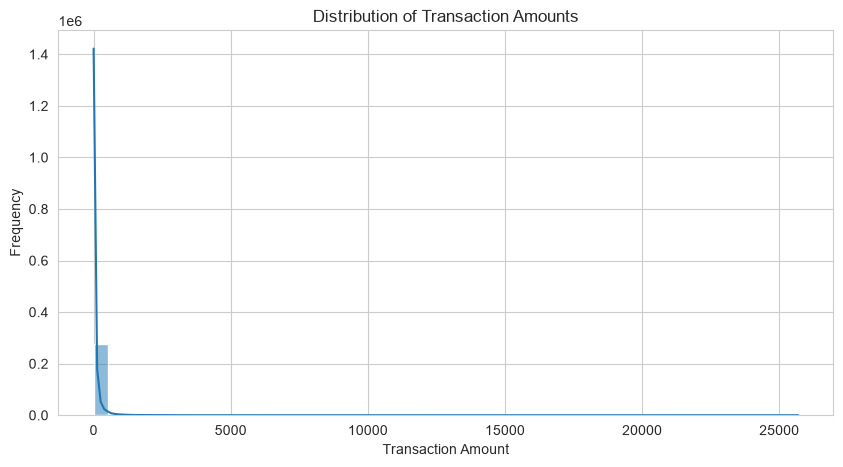

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(df_cleaned["Amount"], bins=50, kde=True)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

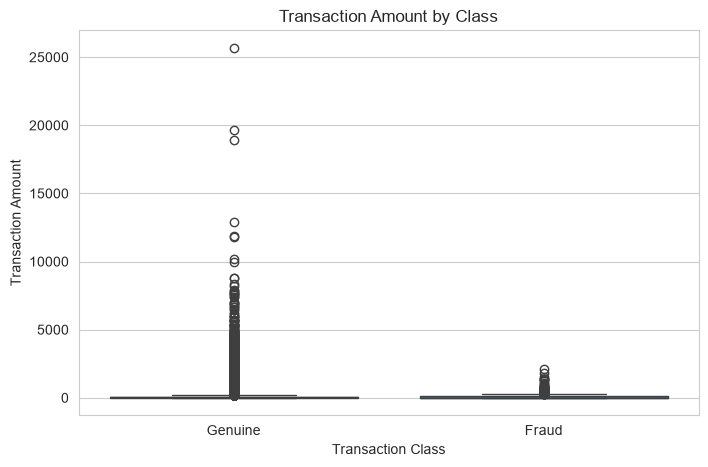

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_cleaned, x="Class", y="Amount")

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Genuine", "Fraud"])

plt.show()

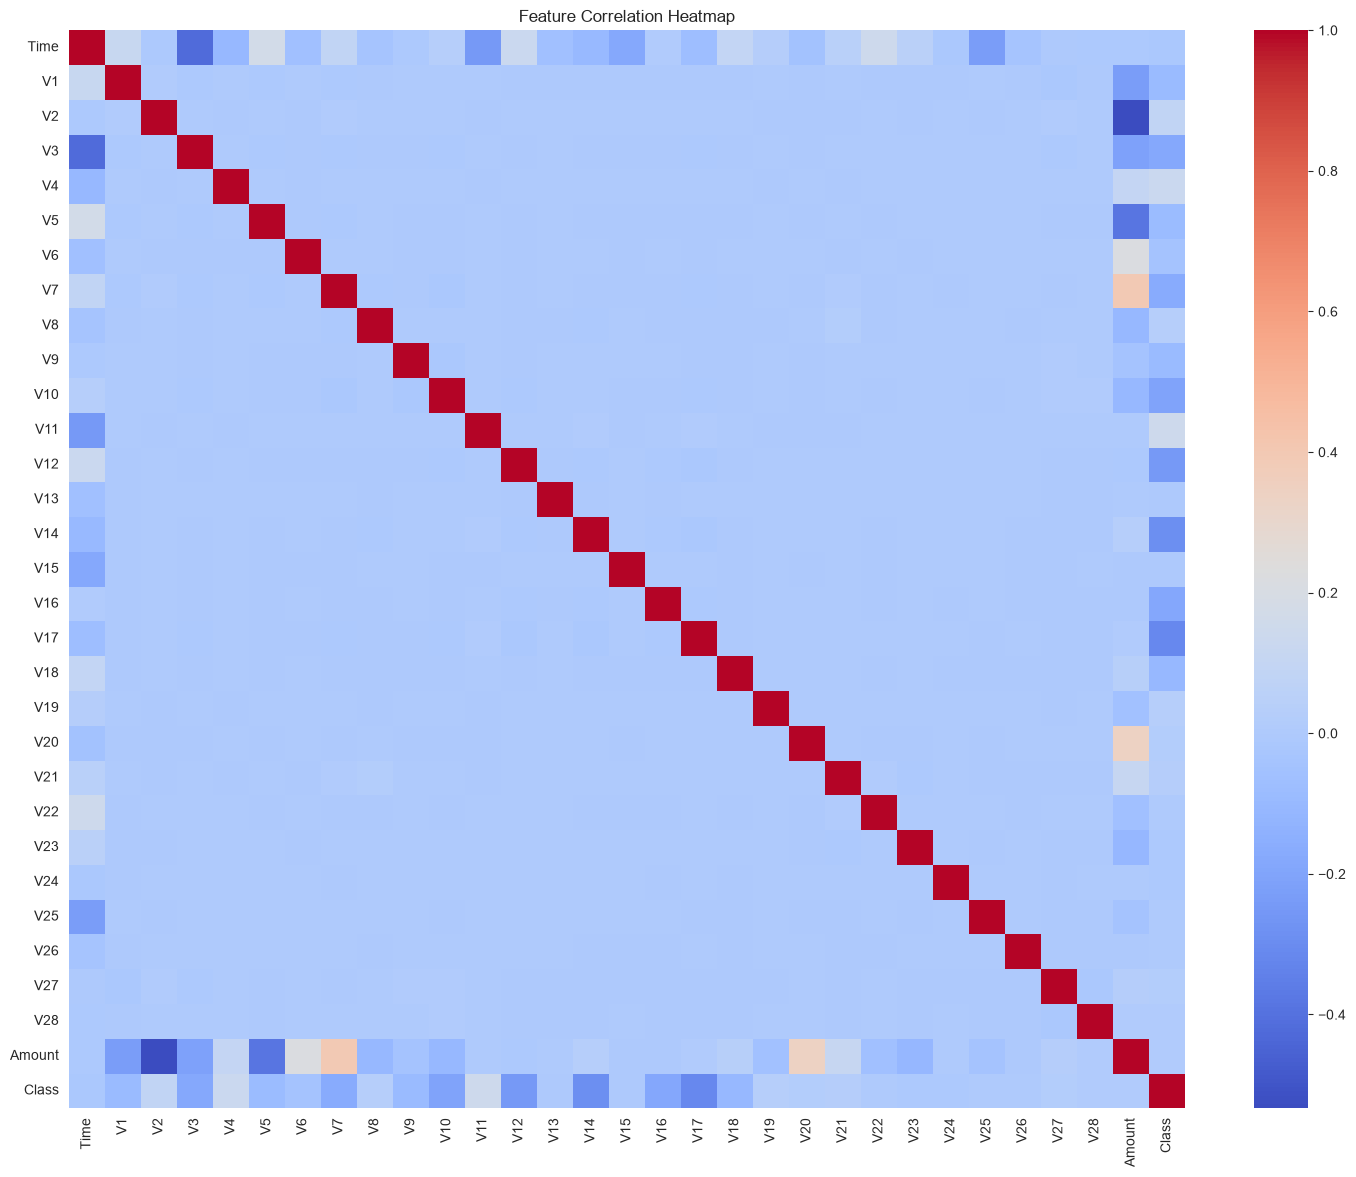

In [14]:
# Calculate correlation between features
correlation = df_cleaned.corr()

# Visualize correlation using heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [15]:
# Find correlation of all features with the target variable
class_correlation = df_cleaned.corr()["Class"]

# Sort correlations by absolute strength
class_correlation = class_correlation.drop("Class")

class_correlation = class_correlation.reindex(
    class_correlation.abs().sort_values(ascending=False).index
)

print("Features most correlated with Class:")
print(class_correlation)

Features most correlated with Class:
V17      -0.313498
V14      -0.293375
V12      -0.250711
V10      -0.206971
V16      -0.187186
V3       -0.182322
V7       -0.172347
V11       0.149067
V4        0.129326
V18      -0.105340
V1       -0.094486
V9       -0.094021
V5       -0.087812
V2        0.084624
V6       -0.043915
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
Time     -0.012359
V28       0.009682
V24      -0.007210
V23      -0.006333
Amount    0.005777
V22       0.004887
V26       0.004265
V13      -0.003897
V15      -0.003300
V25       0.003202
Name: Class, dtype: float64


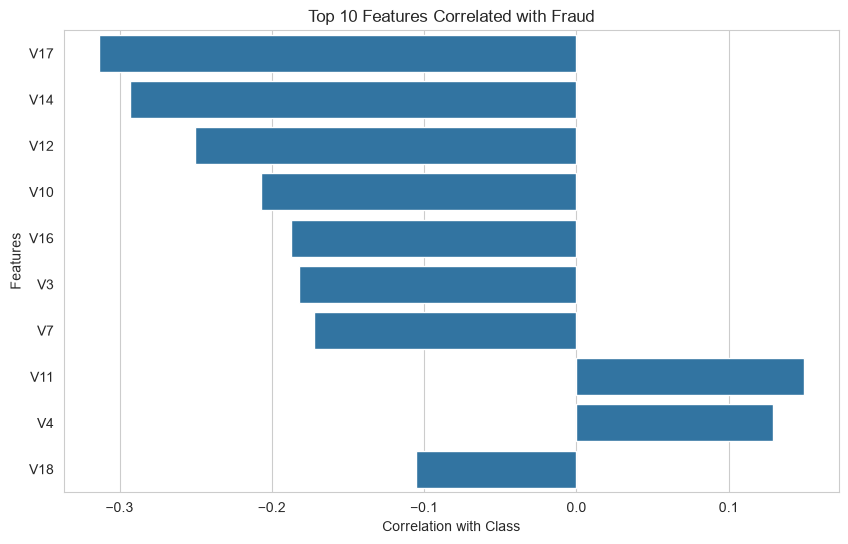

In [16]:
# Select the top 10 features by absolute correlation
top_10_features = class_correlation.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_features.values,
    y=top_10_features.index
)

plt.title("Top 10 Features Correlated with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Features")

plt.show()

## EDA Summary – Credit Card Fraud Detection

### 1. Dataset Overview
- Original dataset contains 284,807 transactions.
- Total features: 30 input features and 1 target variable.
- Target column: `Class` (0 = Genuine, 1 = Fraud).

### 2. Data Quality
- No missing values were found.
- 1,081 duplicate records were identified and removed.
- Final cleaned dataset contains 283,726 transactions.

### 3. Class Distribution
- Genuine transactions: 283,253 (99.83329%).
- Fraudulent transactions: 473 (0.16671%).
- The dataset is highly imbalanced.

### 4. Transaction Amount Analysis
- Average transaction amount: 88.47.
- Median transaction amount: 22.00.
- Maximum transaction amount: 25,691.16.
- Transaction amounts follow a positively skewed distribution.

### 5. Feature Correlation
The features with the strongest absolute correlation with the target include:
- V17: -0.3135
- V14: -0.2934
- V12: -0.2507
- V10: -0.2070
- V16: -0.1872

### 6. Key Observations
- The dataset has a severe class imbalance.
- Accuracy alone will not be a reliable evaluation metric.
- Precision, Recall, F1-score and PR-AUC will be important.
- Class imbalance handling techniques will be explored during preprocessing.
- Feature scaling will be considered for suitable algorithms.

### Conclusion
Exploratory Data Analysis helped us understand the dataset structure, data quality, transaction amount distribution, class imbalance and feature correlations. The cleaned dataset is ready for the preprocessing stage.